preliminary code

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

In [4]:
# function that takes filepath of network and returns network
def extract_to_network(filepath):
    df = pd.read_csv(filepath, header=None) # save csv as dataframe
    matrix = np.asarray(df) # convert dataframe to numpy array
    n_rows, n_cols = matrix.shape # save the shape of the matrix to number of rows and columns variables

    network = nx.Graph() # create empty network

    network.add_nodes_from(range(n_rows), bipartite=0) # add first set of nodes from the rows
    network.add_nodes_from(range(n_rows, n_rows + n_cols), bipartite=1) # add second set of nodes by taking the range of number of rows to the remainder of the columns

    rows, cols = np.nonzero(matrix) # create variables of all rows and columns where there is an edge/a non zero in the matrix
    for row, col in zip(rows, cols): # add an edge where these variables overlap
        network.add_edge(row, n_rows + col)

    largest_CC = max(nx.connected_components(network), key=len) # save the largest connected component of the network
    network = network.subgraph(largest_CC).copy() # replace the network with only the largest component

    return network

# function to randomly remove nodes from the network
def random_removal(network):
    network = network.copy()

    SCC = [len(CC) for CC in nx.connected_components(network)] # saves size of largest component and saves to list
    r_list = [max(SCC, default=0)] # creates list with longest component

    for _ in range(network.number_of_nodes()): # randomly removes node and then saves largest size component and adds to r_list
        node = np.random.choice(list(network.nodes()))
        network.remove_node(node)

        SCC = [len(CC) for CC in nx.connected_components(network)]
        r_list.append(max(SCC, default=0))

    return r_list

# function to remove nodes based on degree centrality/highest degree
def degree_removal(network):
    network = network.copy()

    SCC = [len(CC) for CC in nx.connected_components(network)]
    d_list = [max(SCC, default=0)]

    for _ in range(network.number_of_nodes()): # saves node with highest degree, removes it, adds size of largest component to list
        high_degree = max(network.degree, key=lambda x: x[1])[0]
        network.remove_node(high_degree)

        SCC = [len(CC) for CC in nx.connected_components(network)]
        d_list.append(max(SCC, default=0))

    return d_list

# function to remove nodes based on harmoic centrality
def harmonic_removal(network):
    network = network.copy()

    SCC = [len(CC) for CC in nx.connected_components(network)]
    h_list = [max(SCC, default=0)]

    for _ in range(network.number_of_nodes()):
        centrality = nx.harmonic_centrality(network)
        high = max(centrality, key=centrality.get)
        network.remove_node(high)

        SCC = [len(CC) for CC in nx.connected_components(network)]
        h_list.append(max(SCC, default=0))

    return h_list

# function to remove nodes based on eigenvector centrality, max_iter 10000 to prevent failures by trying several times
def eigen_removal(network, max_iter=10000):
    network = network.copy()

    SCC = [len(CC) for CC in nx.connected_components(network)]
    e_list = [max(SCC, default=0)]

    for _ in range(network.number_of_nodes()):
        centrality = nx.eigenvector_centrality(network, max_iter=max_iter)
        high = max(centrality, key=centrality.get)
        network.remove_node(high)

        SCC = [len(CC) for CC in nx.connected_components(network)]
        e_list.append(max(SCC, default=0))

    return e_list

# function to remove nodes based on betweenness centrality
def between_removal(network):
    network = network.copy()

    SCC = [len(CC) for CC in nx.connected_components(network)]
    b_list = [max(SCC, default=0)]

    for _ in range(network.number_of_nodes()):
        centrality = nx.betweenness_centrality(network)
        high = max(centrality, key=centrality.get)
        network.remove_node(high)

        SCC = [len(CC) for CC in nx.connected_components(network)]
        b_list.append(max(SCC, default=0))

    return b_list

# plots all removals on a single plot
def plot_removal(network):
    results = {
        'Random': random_removal(network),
        'Degree': degree_removal(network),
        'Harmonic': harmonic_removal(network),
        'Eigenvector': eigen_removal(network),
        'Betweenness': between_removal(network)
    } # saves results of removals to dictionary with name of each removal

    plt.figure(figsize=(12, 5))
    for label, sizes in results.items(): # plots each removal while labeling with removals name
        plt.plot(range(len(sizes)), sizes, label=label)

    plt.xlabel('Number of nodes removed')
    plt.ylabel('Giant Component (nodes)')
    plt.title('Network Robustness')
    plt.legend()
    plt.ylim(bottom=0) # plot bottoms out at 0
    plt.xlim(0) # plot starts at 0
    plt.tight_layout()
    plt.show()

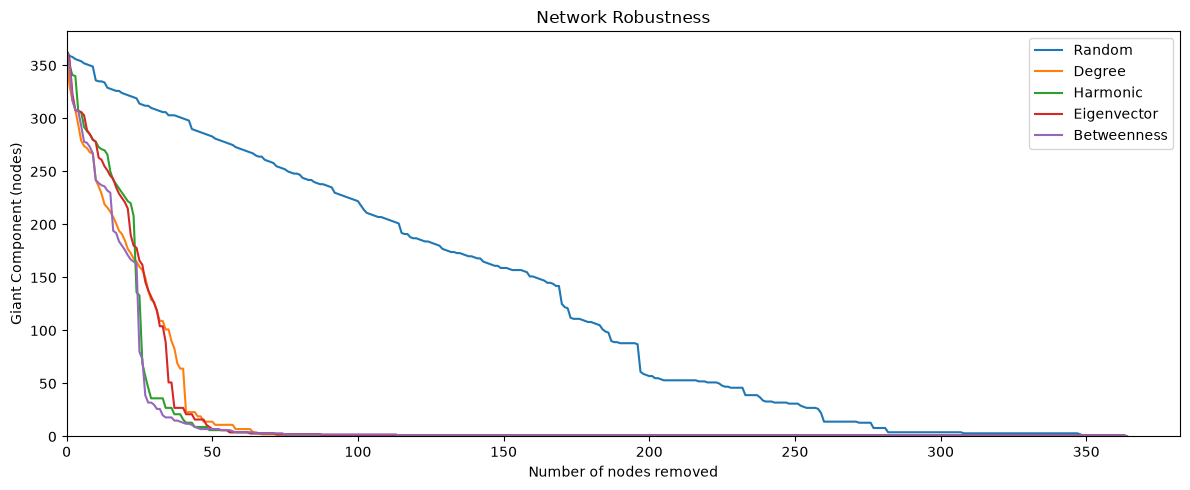

In [5]:
yamazaki = extract_to_network('../data/web-of-life_2026-10-22_203340/M_PL_053.csv')
plot_removal(yamazaki)